# Sources recovered by the Gaia proper-motion fix

`proper_motion_filter` used to reject any source whose Gaia match had a masked proper
motion, treating a 2-parameter (position-only) solution as evidence of a fast mover.
Gaia publishes no proper motion at all for 2p solutions, and 2p is assigned on data
quality (Lindegren+2021 Eq. 21: `G <= 21.0 & N_vpu >= 9 & sigma5d_max`), not kinematics.
That branch was removed in PR #2, and the catalog is being refiltered into
`filter_results_9_21_2026_full_catalog_fixed_pm`.

This notebook finds the sources that differ between the new run and the 9/13 run, and
plots them.

## cat 0 -- explained, and verified

Over 109 fields: **11,731 gained against 49 lost**, and **96.8%** of the gains match a
Gaia source within a few tenths of an arcsec that has masked `pm` and
`astrometric_params_solved = 3` -- exactly the condition the old code rejected on. The
per-filter diff agrees: `proper_motion_filter` pass rate went 78.48% -> 94.55% while
every other filter is byte-identical. That is the PM fix, and nothing else.

## cat 1 -- not the PM fix, cause still open

cat 1 gained 701 but **lost 190**, and **90.6%** of its gains have no Gaia match within 5"
at all, so the proper-motion filter never touched them. Removing a rejection branch cannot
lose sources, so something else is moving cat 1.

Ruled out by direct test:

| candidate | verdict |
|---|---|
| the PM fix | can only add; 90.6% of gains have no Gaia match |
| nondeterminism | field 000276 re-run reproduces itself exactly (cat0 313/313, cat1 9/9) |
| `1b3ee3e` (SIMBAD) | A/B on field 000872: pre- and post-SIMBAD both give cat1 = **2495**, identical |
| changed input catalogs | 1335 field catalogs date from 9/12, before both runs |
| KDE grid change (`cebc380`) | envelopes are cached and shared; `only_big_dmag` counts byte-identical |

What remains is that the 9/13 run executed code that no longer exists in any commit. It
was launched 9/13 while `cebc380` (committed 9/14 16:12), `8a4fa1f` (pulled 9/14 17:09)
and `1e6adc9` (pulled 9/15) were landing, and the cluster carried uncommitted edits then.
**So the 9/13 catalog is not a clean baseline for cat 1.** The cells at the bottom sample
both the gained and the lost so the difference can be inspected directly.

In [1]:
import os
import sys

import h5py
import numpy as np
import pandas as pd
import astropy.units as u
import matplotlib.pyplot as plt

from glob import glob
from astropy.table import Table, meta as table_meta, serialize
from astropy.coordinates import SkyCoord

sys.path.append('/Users/adamboesky/Research/long_transients')
sys.path.append('/n/home04/aboesky/berger/long_transients')

from Extracting.utils import get_data_path
from Source_Analysis.Sources import Source, Sources

STUDY = f'{get_data_path()}/filtered_out_study'
NEW_RUN = f'{STUDY}/new_run'          # per-field 0/1.hdf5 rsynced from cannon
OLD_RUN = f'{get_data_path()}/filter_results_9_13_2026_full_catalog'

CasJobs will use the credentials from mast_dino_login.txt


In [2]:
# Row-selective HDF5 loader (same one used in masterson.ipynb). Reads only the requested
# records: Sources.from_table costs ~9 ms/row, so never build the whole table.
def load_ecsv_rows(fpath: str, rows, path: str = 'data') -> Table:
    """Same result as load_ecsv(fpath)[rows], but only those records come off disk."""
    if fpath.endswith('.ecsv'):
        fpath = f'{fpath[:-5]}.hdf5'
    rows = np.atleast_1d(np.asarray(rows, dtype=int))

    with h5py.File(fpath, 'r') as f:
        dset = f[path]
        uniq, inverse = np.unique(rows, return_inverse=True)
        table = Table(dset[uniq.tolist()][inverse], copy=False)

        meta_name = f'{path}.__table_column_meta__'
        if meta_name in f:
            header = table_meta.get_header_from_yaml(h.decode('utf-8') for h in f[meta_name])
            if 'meta' in header:
                table.meta = header['meta']
            header_cols = {x['name']: x for x in header['datatype']}
            for col in table.columns.values():
                for attr in ('description', 'format', 'unit', 'meta'):
                    if attr in header_cols[col.name]:
                        setattr(col, attr, header_cols[col.name][attr])
            table = serialize._construct_mixins_from_columns(table)
        else:
            table.meta.update(dset.attrs)

    return table


def sources_from_rows(fpath: str, rows, **kwargs) -> Sources:
    """Sources for the given row indices, with the filtering_dirpath from_file derives."""
    if 'filtering_dirpath' not in kwargs:
        parent = os.path.dirname(os.path.abspath(fpath))
        kwargs['filtering_dirpath'] = parent if glob(os.path.join(parent, '*_filtered_out.ecsv')) \
                                      else os.path.dirname(parent)
    return Sources.from_table(load_ecsv_rows(fpath, rows), **kwargs)

In [3]:
# Find sources in the new run with no counterpart in the old one.
#
# Only combined/ exists locally for the 9/13 run (the per-field dirs live on cannon), so
# match each new per-field source against the old *combined* catalog for that cat. Same
# comparison, since combined is just the per-field results stacked.
MATCH_ARCSEC = 1.0

old_cat = {}
for cat in ('0', '1'):
    with h5py.File(f'{OLD_RUN}/combined/{cat}.hdf5', 'r') as h:
        rd = h['data'].fields(['ra', 'dec'])[:]
    old_cat[cat] = SkyCoord(rd['ra'] * u.deg, rd['dec'] * u.deg)
    print(f'old combined cat {cat}: {len(rd)} sources')

recovered = []
for field_dir in sorted(glob(f'{NEW_RUN}/*/')):
    field = os.path.basename(field_dir.rstrip('/'))
    for cat in ('0', '1'):
        new_p = f'{NEW_RUN}/{field}/{cat}.hdf5'
        if not os.path.exists(new_p):
            continue
        with h5py.File(new_p, 'r') as h:
            new = h['data'].fields(['ra', 'dec'])[:]
        if len(new) == 0:
            continue
        new_c = SkyCoord(new['ra'] * u.deg, new['dec'] * u.deg)
        _, sep, _ = new_c.match_to_catalog_sky(old_cat[cat])
        for i in np.flatnonzero(sep.arcsec > MATCH_ARCSEC):
            recovered.append({'field': field, 'cat': cat, 'row': int(i),
                              'ra': float(new['ra'][i]), 'dec': float(new['dec'][i])})

recovered = pd.DataFrame(recovered, columns=['field', 'cat', 'row', 'ra', 'dec'])
recovered.to_csv(f'{STUDY}/recovered_sources_rows.csv', index=False)
print(f'\n{len(recovered)} recovered sources across {recovered["field"].nunique()} fields')
print(recovered.groupby('cat').size().to_string())
recovered.head()

old combined cat 0: 158876 sources
old combined cat 1: 10170 sources

2334 recovered sources across 26 fields
cat
0    2211
1     123


,field,cat,row,ra,dec
0,000276,0,1,229.556560,-24.097908
1,000276,0,3,231.313906,-26.272912
2,000276,0,6,231.284522,-26.766674
3,000276,0,8,227.686071,-23.787100
4,000276,0,9,226.351197,-26.876583


In [4]:
# plot_everything() hits the network per source (light curves, spectra, cutouts), so pick
# a small sample rather than all ~2200. Bump N_PER_CAT, or set `sample` by hand below.
N_PER_CAT = 4

sample = pd.concat([g.sample(min(N_PER_CAT, len(g)), random_state=0)
                    for _, g in recovered.groupby('cat')], ignore_index=True)

recovered_srcs = {}
for (field, cat), grp in sample.groupby(['field', 'cat']):
    fpath = f'{NEW_RUN}/{field}/{cat}.hdf5'
    for (_, r), src in zip(grp.iterrows(), sources_from_rows(fpath, grp['row'].tolist())):
        recovered_srcs[(field, cat, r['row'])] = src
        print(f'cat {cat}  fld {field}  ({src.ra:.5f}, {src.dec:+.5f})')

print(f'\n{len(recovered_srcs)} Source objects built')

cat 1  fld 000295  (6.28897, -15.51397)
cat 0  fld 000298  (27.11851, -18.55499)
cat 0  fld 000303  (63.10067, -18.11505)
cat 0  fld 000304  (73.94058, -18.70857)
cat 0  fld 000316  (153.53275, -20.20857)
cat 1  fld 000316  (155.61340, -19.73460)
cat 1  fld 000317  (161.02441, -14.03470)
cat 1  fld 000320  (182.36215, -16.36984)

8 Source objects built


## Plots

One `plot_everything()` per recovered source. This is the slow part -- each call queries
ZTF/WISE/NEOWISE/PTF/SDSS/PanSTARRS/Gaia light curves plus cutouts.

In [7]:
for (field, cat, row), src in recovered_srcs.items():
    print(f'\n{"=" * 90}\ncat {cat}   field {field}   row {row}   '
          f'({src.ra:.5f}, {src.dec:+.5f})\n{"=" * 90}', flush=True)
    try:
        src.plot_everything()
        plt.show()
    except Exception as e:
        print(f'  plot_everything failed: {type(e).__name__}: {e}')


cat 1   field 000295   row 10   (6.28897, -15.51397)


KeyboardInterrupt: 

In [ ]:
# Plot a specific source instead:
#   src = sources_from_rows(f'{NEW_RUN}/000313/0.hdf5', [42])[0]
#   src.plot_everything()

---

# cat 1: what was gained, and what was lost

The PM fix can only add sources, so the losses are the interesting half -- they are the
direct evidence that something other than the fix is moving cat 1. Below, both
populations are identified per field (using the per-field catalogs from *both* runs, so
fields the new run has not reached yet are excluded rather than counted as losses), then
a sample of each is plotted.

- **gained** -- in the new run's `1.hdf5`, no counterpart within 1" in the old run's
- **lost** -- in the old run's `1.hdf5`, no counterpart within 1" in the new run's

In [8]:
# Per-field cat-1 diff, both directions. OLD_PERFIELD holds the 9/13 run's per-field
# 1.hdf5 files (rsynced from cannon); only fields present in both runs are considered.
OLD_PERFIELD = f'{STUDY}/old_run'
TOL = 1.0  # arcsec


def unmatched(a, b, tol=TOL):
    """Indices of rows in `a` with no counterpart within tol of anything in `b`."""
    if len(a) == 0:
        return np.array([], dtype=int)
    if len(b) == 0:
        return np.arange(len(a))
    _, sep, _ = SkyCoord(a['ra'] * u.deg, a['dec'] * u.deg).match_to_catalog_sky(
        SkyCoord(b['ra'] * u.deg, b['dec'] * u.deg))
    return np.flatnonzero(sep.arcsec > tol)


def radec(path):
    with h5py.File(path, 'r') as h:
        return h['data'].fields(['ra', 'dec'])[:]


gained, lost = [], []
n_fields = 0
for field_dir in sorted(glob(f'{NEW_RUN}/*/')):
    field = os.path.basename(field_dir.rstrip('/'))
    np_, op_ = f'{NEW_RUN}/{field}/1.hdf5', f'{OLD_PERFIELD}/{field}/1.hdf5'
    if not (os.path.exists(np_) and os.path.exists(op_)):
        continue
    new, old = radec(np_), radec(op_)
    n_fields += 1
    for i in unmatched(new, old):
        gained.append({'field': field, 'row': int(i), 'ra': float(new['ra'][i]),
                       'dec': float(new['dec'][i]), 'which': 'gained'})
    for i in unmatched(old, new):
        lost.append({'field': field, 'row': int(i), 'ra': float(old['ra'][i]),
                     'dec': float(old['dec'][i]), 'which': 'lost'})

gained = pd.DataFrame(gained, columns=['field', 'row', 'ra', 'dec', 'which'])
lost = pd.DataFrame(lost, columns=['field', 'row', 'ra', 'dec', 'which'])
pd.concat([gained, lost]).to_csv(f'{STUDY}/cat1_gained_lost.csv', index=False)

print(f'{n_fields} fields present in both runs')
print(f'  cat 1 GAINED: {len(gained):5d}   (in new, not old)')
print(f'  cat 1 LOST:   {len(lost):5d}   (in old, not new)  <- the PM fix cannot cause these')
print(f'\nwrote {STUDY}/cat1_gained_lost.csv')

226 fields present in both runs
  cat 1 GAINED:   824   (in new, not old)
  cat 1 LOST:     200   (in old, not new)  <- the PM fix cannot cause these

wrote /Users/adamboesky/Research/long_transients/Data/filtered_out_study/cat1_gained_lost.csv


In [9]:
# Build Source objects for a sample of each. Gained sources are read from the new run's
# catalog, lost ones from the 9/13 run's -- each from the catalog it actually exists in.
N_SAMPLE = 3

cat1_srcs = {}
for label, df, base in (('gained', gained, NEW_RUN), ('lost', lost, OLD_PERFIELD)):
    if len(df) == 0:
        print(f'no {label} sources')
        continue
    samp = df.sample(min(N_SAMPLE, len(df)), random_state=0)
    for field, grp in samp.groupby('field'):
        fpath = f'{base}/{field}/1.hdf5'
        for (_, r), src in zip(grp.iterrows(), sources_from_rows(fpath, grp['row'].tolist())):
            cat1_srcs[(label, field, r['row'])] = src
            print(f'  {label:6s} fld {field}  ({src.ra:.5f}, {src.dec:+.5f})')

print(f'\n{len(cat1_srcs)} Source objects built '
      f'({sum(k[0] == "gained" for k in cat1_srcs)} gained, '
      f'{sum(k[0] == "lost" for k in cat1_srcs)} lost)')

  gained fld 000294  (4.99732, -13.83713)
  gained fld 000301  (51.89081, -18.21371)
  gained fld 000317  (161.02441, -14.03470)
  lost   fld 000395  (358.26699, -13.04933)
  lost   fld 000871  (123.24579, +82.98060)
  lost   fld 000872  (146.95428, +82.30390)

6 Source objects built (3 gained, 3 lost)


Querying metadata from https://irsa.ipac.caltech.edu/ibe/search/ztf/products/deep?WHERE=field=000294+AND+ccdid=13+AND+qid=1

Image downloaded and saved at /var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/tmpsf_lnkaf/ztf_000294_zr_c13_q1_refimg.fits
Image downloaded and saved at /var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/tmpa33v3re3/ztf_000294_zi_c13_q1_refimg.fits
Image downloaded and saved at /var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/tmp9btwv0n9/ztf_000294_zg_c13_q1_refimg.fits
Querying ztf catalog for light curve...Querying wise catalog for light curve...

Querying neowise catalog for light curve...
Querying ptf catalog for light curve...
Querying sdss catalog for light curve...
Querying panstarrs catalog for light curve...
Querying gaia catalog for light curve...
Querying custom catalog for light curve...
Source at (4.997322435958698, -13.837130393053641) has no spectrum in SDSS.
Getting source spectrum from DESI DR1 (SPARCL)...
Source at (4.997322435958698, -13.8371303

array([array([[<Axes: ylabel='\\textbf{Pan-STARRS}'>, <Axes: >, <Axes: >],
              [<Axes: xlabel='\\textbf{g}', ylabel='\\textbf{ZTF}'>,
               <Axes: xlabel='\\textbf{r}'>, <Axes: xlabel='\\textbf{i}'>]],
             dtype=object)                                                  ,
       <Axes: xlabel='\\textbf{Time [mjd]}', ylabel='\\textbf{Mag}'>,
       <Axes: xlabel='\\textbf{Wavelength [\\AA]}', ylabel='\\boldmath$F_\\lambda \\ [10^{-17} \\ \\rm{erg} \\ \\rm{cm}^{-2} \\ \\rm{s}^{-1} \\ \\rm{\\AA}^{-1}]$'>,
       <Axes: xlabel='\\textbf{Time [mjd]}', ylabel='\\textbf{Mag}'>,
       <Axes: xlabel='\\textbf{W1 - W2}', ylabel='\\textbf{Number}'>],
      dtype=object)

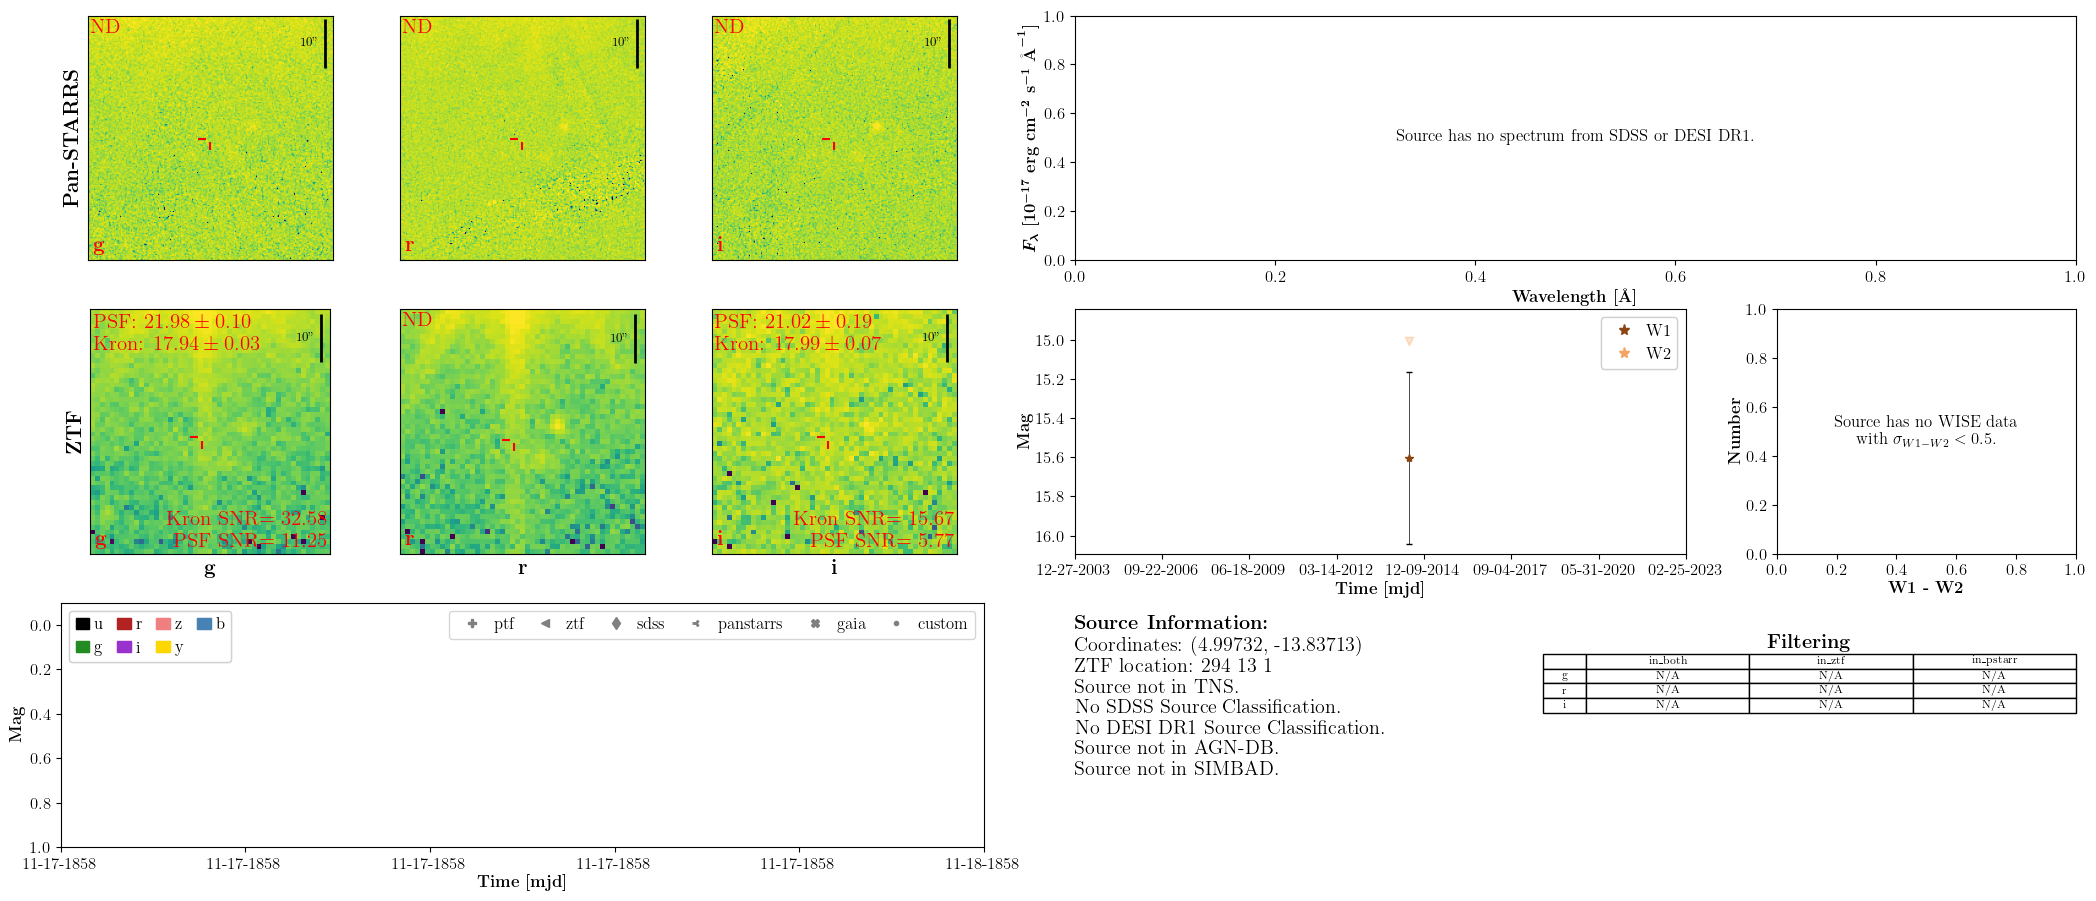

In [15]:
cat1_srcs[('gained', '000294', 7)].plot_everything()

('gained', '000294', 7)


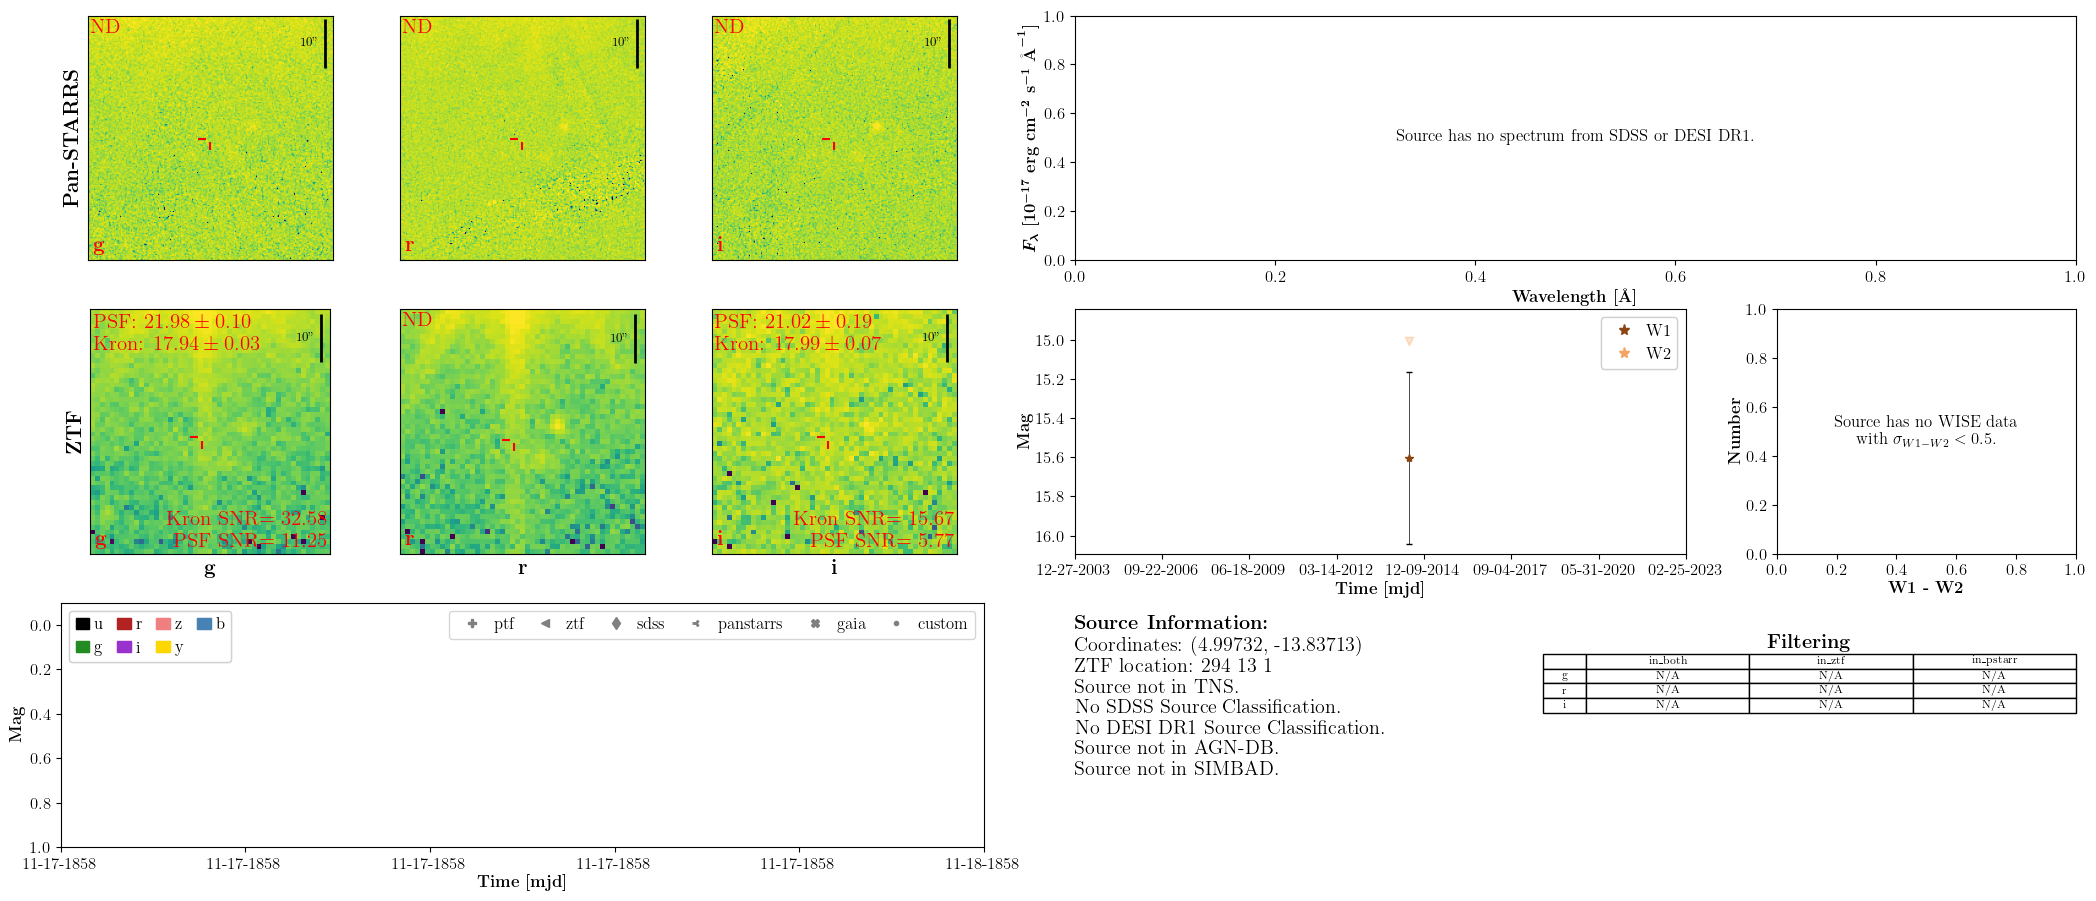

('gained', '000301', 14)
Querying metadata from https://irsa.ipac.caltech.edu/ibe/search/ztf/products/deep?WHERE=field=000301+AND+ccdid=06+AND+qid=3
Image downloaded and saved at /var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/tmpa9_uf2j2/ztf_000301_zi_c06_q3_refimg.fits
Image downloaded and saved at /var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/tmp2pxl0i_o/ztf_000301_zg_c06_q3_refimg.fits
Image downloaded and saved at /var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/tmpgrda8qr5/ztf_000301_zr_c06_q3_refimg.fits
Querying ztf catalog for light curve...Querying wise catalog for light curve...

Querying neowise catalog for light curve...
Querying ptf catalog for light curve...
Querying sdss catalog for light curve...
Querying panstarrs catalog for light curve...
Querying gaia catalog for light curve...
Querying custom catalog for light curve...
Source at (51.890812960645, -18.213707479233047) has no spectrum in SDSS.
Getting source spectrum from DESI DR1 (SPARCL)...
Source at (51.89081

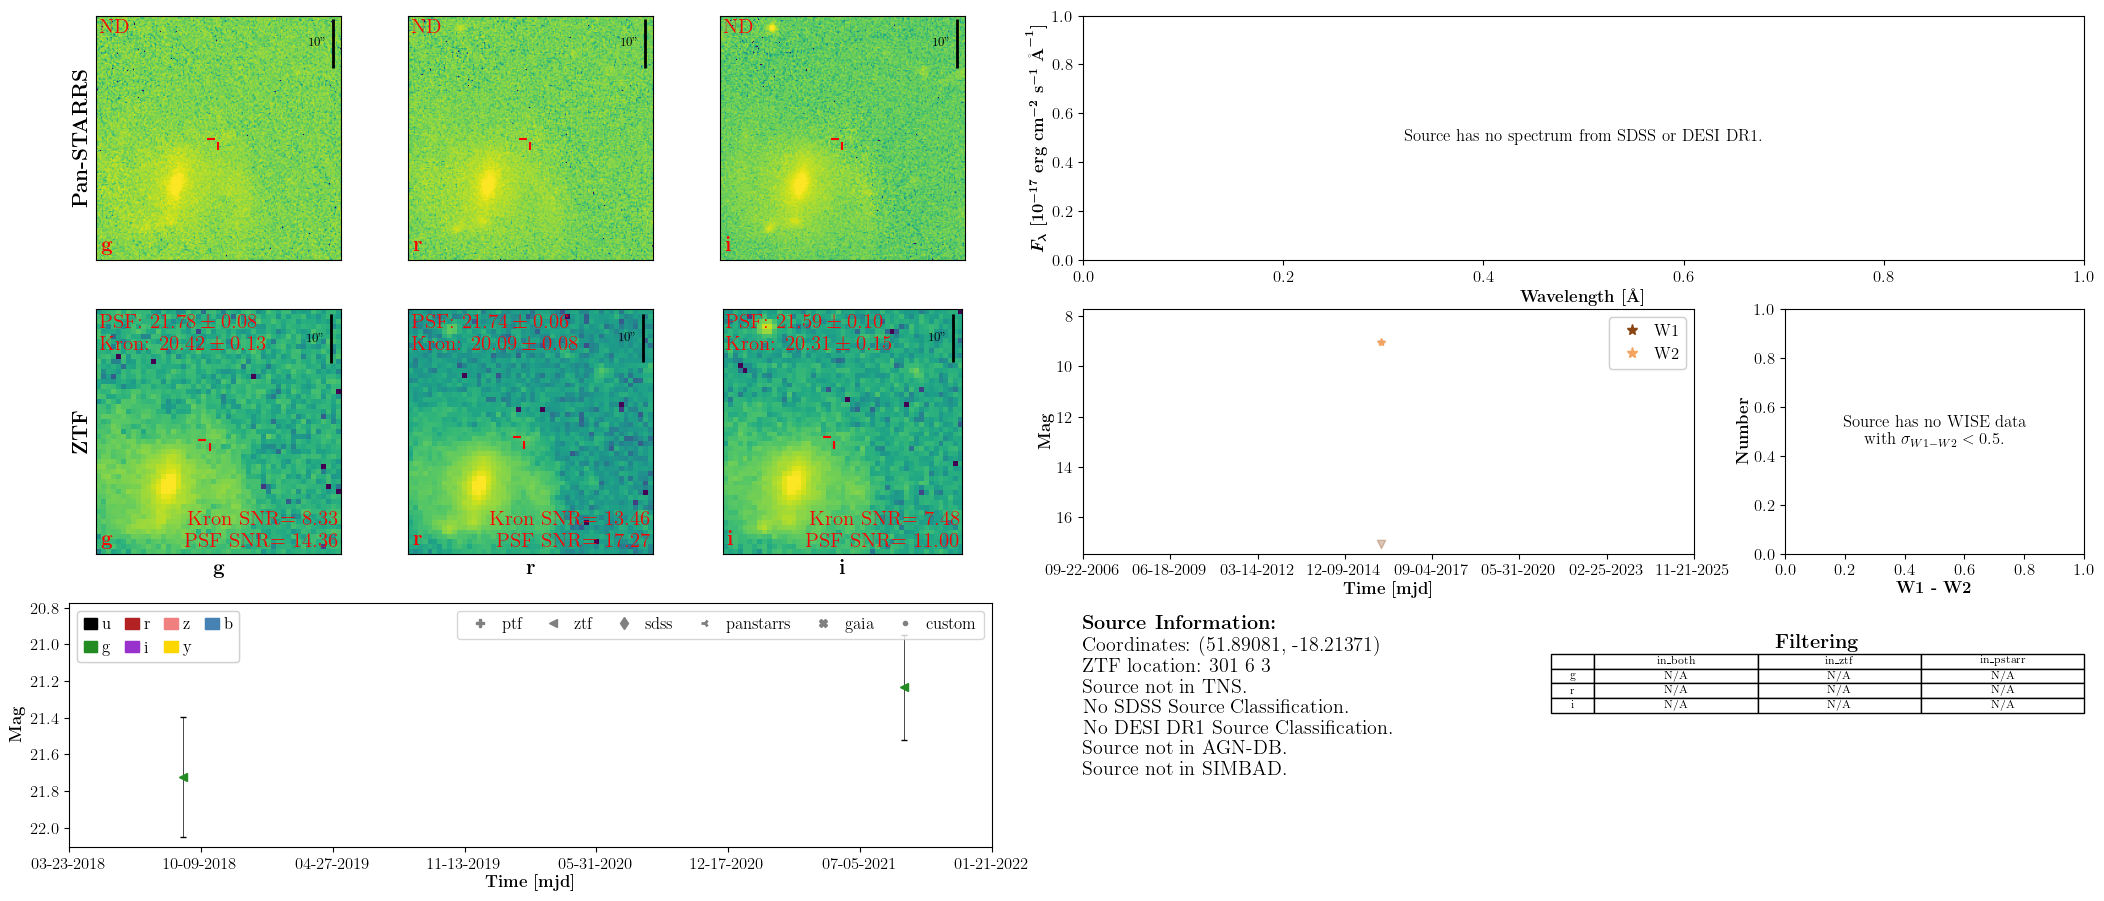

('gained', '000317', 46)
Querying metadata from https://irsa.ipac.caltech.edu/ibe/search/ztf/products/deep?WHERE=field=000317+AND+ccdid=16+AND+qid=2
Image downloaded and saved at /var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/tmpaf45c86d/ztf_000317_zi_c16_q2_refimg.fits
Image downloaded and saved at /var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/tmpthosoodc/ztf_000317_zr_c16_q2_refimg.fits
Image downloaded and saved at /var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/tmpunqhhs4l/ztf_000317_zg_c16_q2_refimg.fits
Querying ztf catalog for light curve...Querying wise catalog for light curve...

Querying neowise catalog for light curve...
Querying ptf catalog for light curve...
Querying sdss catalog for light curve...
Querying panstarrs catalog for light curve...
Querying gaia catalog for light curve...
Querying custom catalog for light curve...
Source at (161.0244063402253, -14.034702466468572) has no spectrum in SDSS.
Getting source spectrum from DESI DR1 (SPARCL)...
Source at (161.02

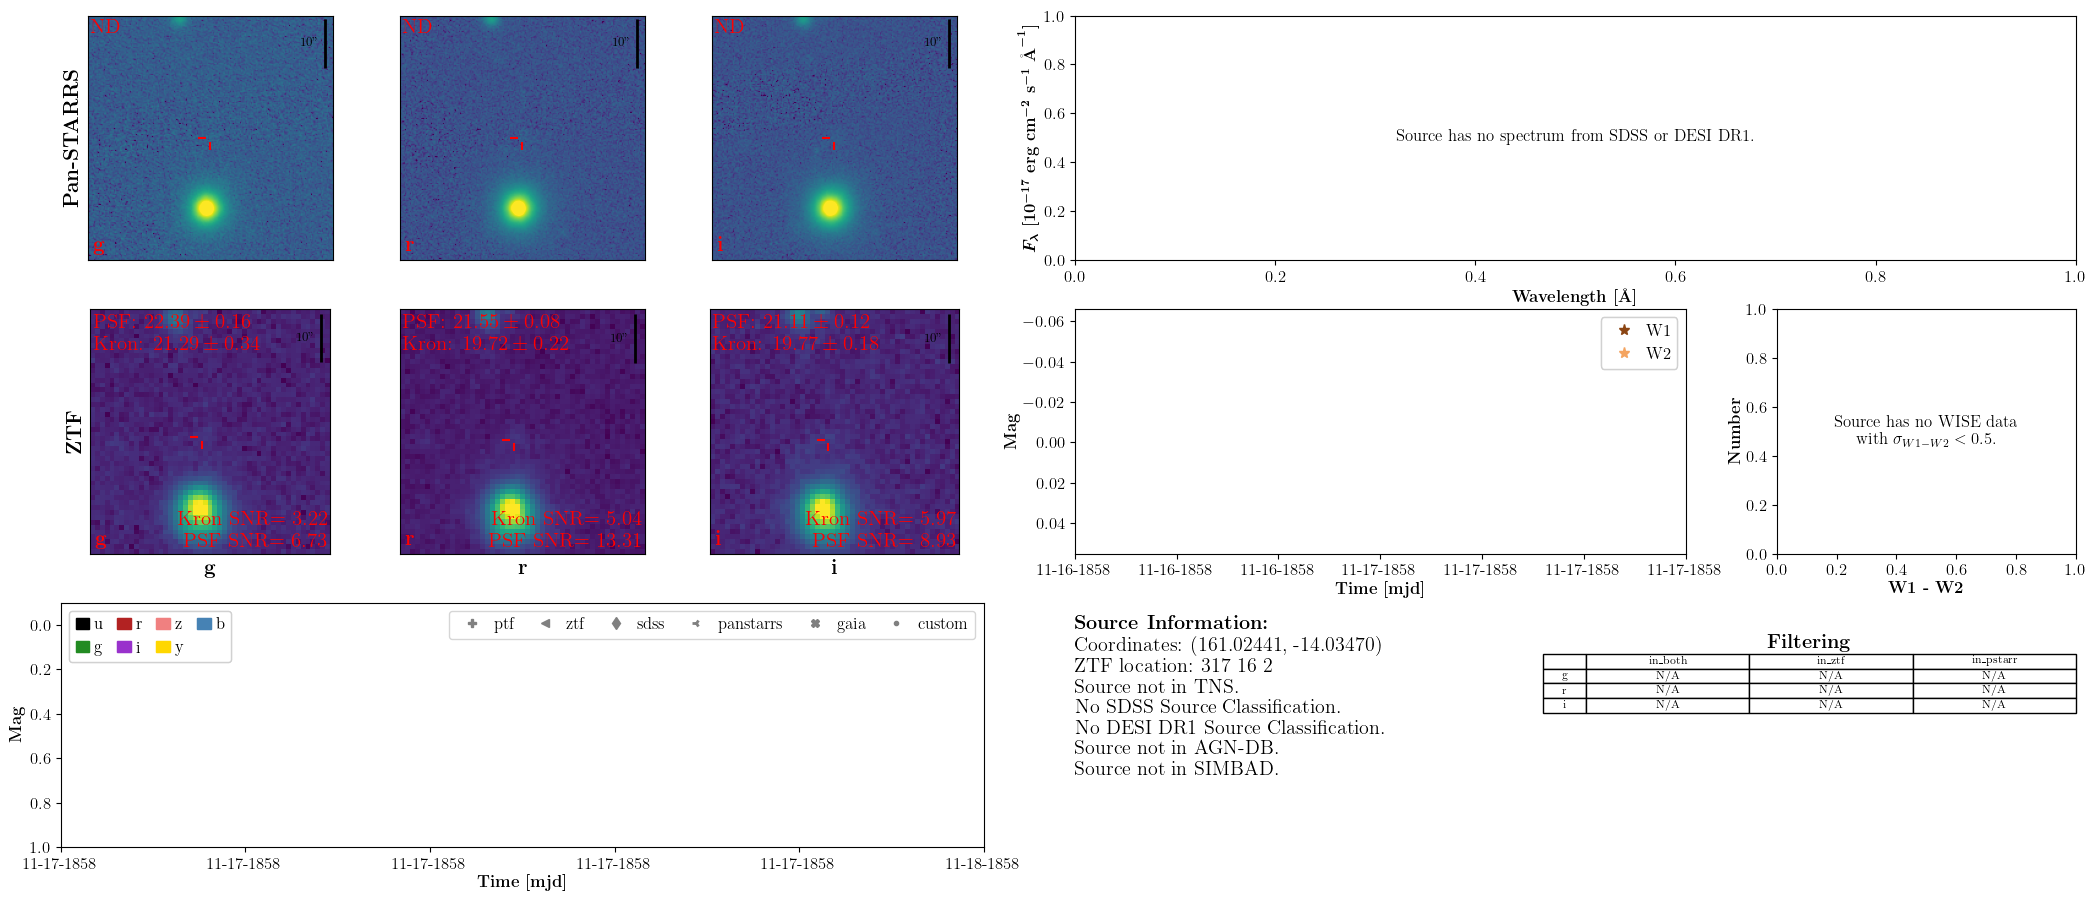

('lost', '000395', 9)
Querying metadata from https://irsa.ipac.caltech.edu/ibe/search/ztf/products/deep?WHERE=field=000395+AND+ccdid=02+AND+qid=3

Image downloaded and saved at /var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/tmptamidqrp/ztf_000395_zg_c02_q3_refimg.fits
Image downloaded and saved at /var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/tmpwg6rt1qo/ztf_000395_zi_c02_q3_refimg.fits
Image downloaded and saved at /var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/tmpwxc7eec7/ztf_000395_zr_c02_q3_refimg.fits
Querying ztf catalog for light curve...Querying wise catalog for light curve...

Querying neowise catalog for light curve...
Querying ptf catalog for light curve...
Querying sdss catalog for light curve...
Querying panstarrs catalog for light curve...
Querying gaia catalog for light curve...
Querying custom catalog for light curve...
Attempt 1 / 3 to query for light curves failed. Trying again...


Traceback (most recent call last):
  File "/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/urllib3/connection.py", line 199, in _new_conn
    sock = connection.create_connection(
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/urllib3/util/connection.py", line 85, in create_connection
    raise err
  File "/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/urllib3/util/connection.py", line 73, in create_connection
    sock.connect(sa)
TimeoutError: timed out

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/urllib3/connectionpool.py", line 789, in urlopen
    response = self._make_request(
               ^^^^^^^^^^^^^^^^^^^
  File "/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.1

Attempt 2 / 3 to query for light curves failed. Trying again...


Traceback (most recent call last):
  File "/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/urllib3/connection.py", line 199, in _new_conn
    sock = connection.create_connection(
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/urllib3/util/connection.py", line 85, in create_connection
    raise err
  File "/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/urllib3/util/connection.py", line 73, in create_connection
    sock.connect(sa)
TimeoutError: timed out

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/urllib3/connectionpool.py", line 789, in urlopen
    response = self._make_request(
               ^^^^^^^^^^^^^^^^^^^
  File "/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.1

Source at (358.2669881361667, -13.049326422677316) has no spectrum in SDSS.
Getting source spectrum from DESI DR1 (SPARCL)...
Source at (358.2669881361667, -13.049326422677316) has no spectrum in DESI DR1.


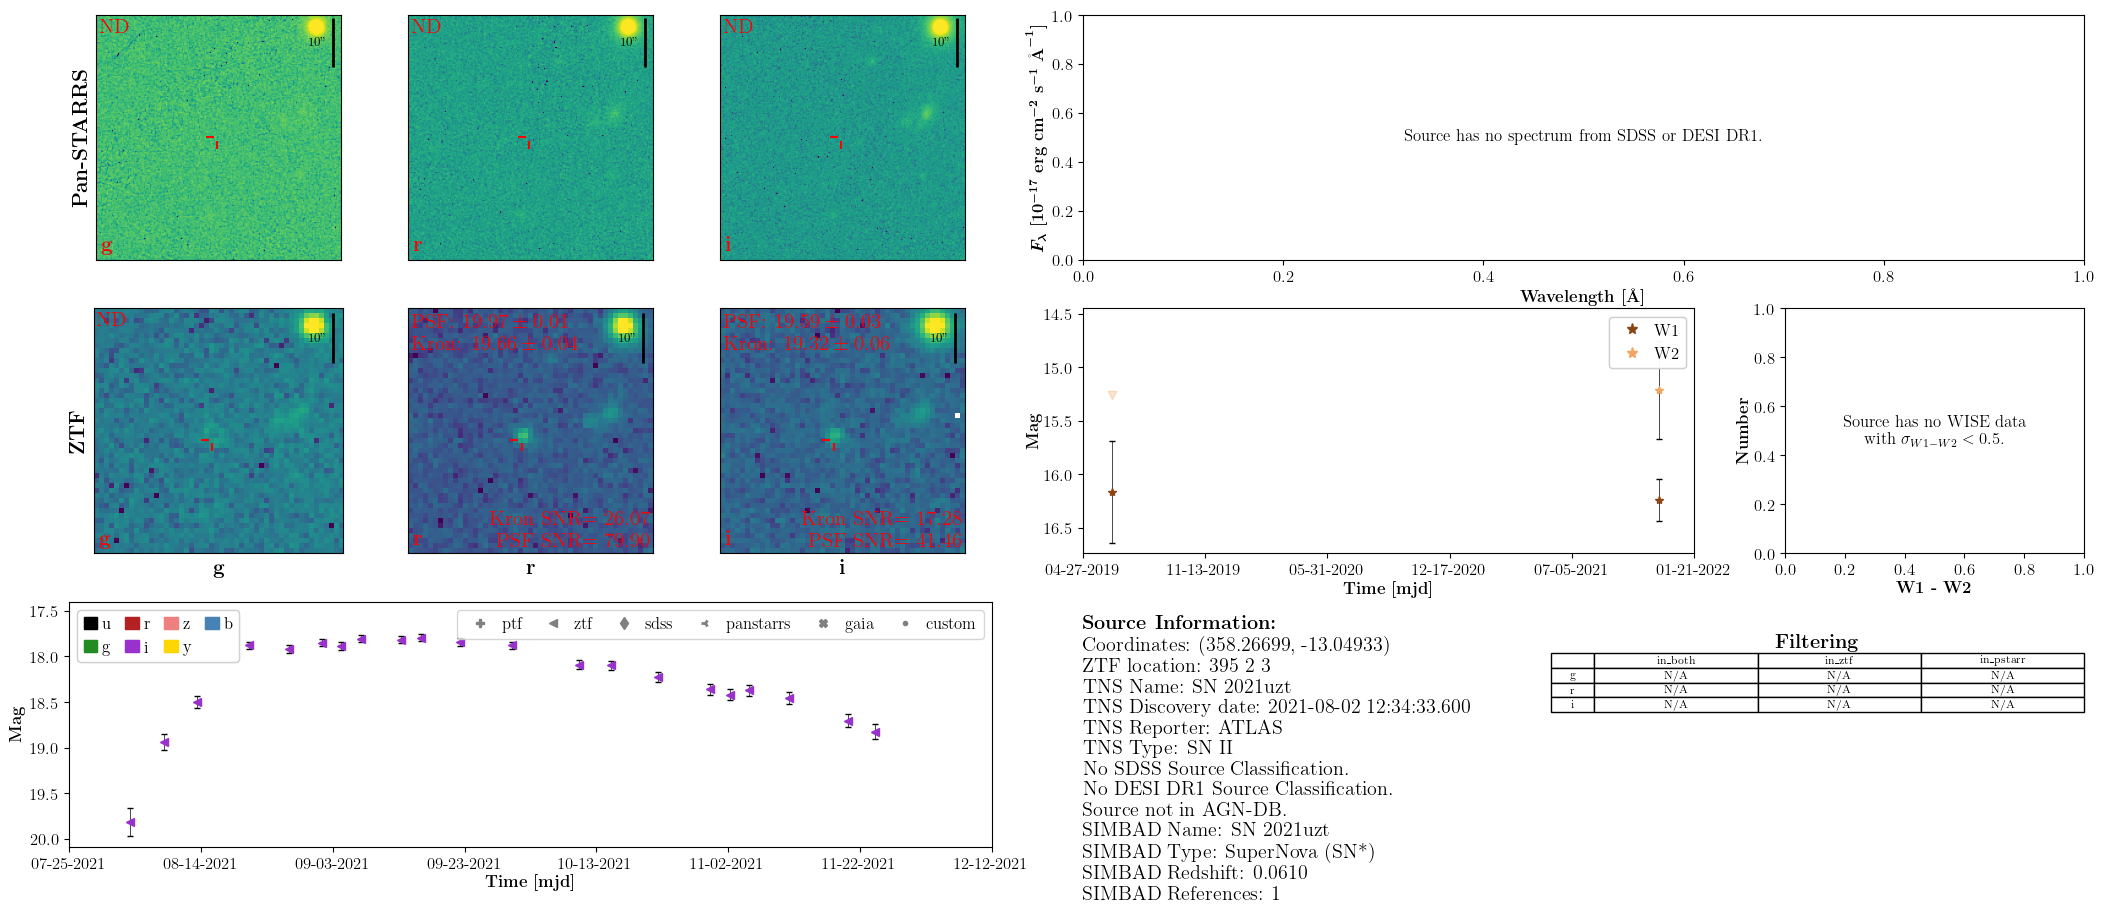

('lost', '000871', 634)
Querying metadata from https://irsa.ipac.caltech.edu/ibe/search/ztf/products/deep?WHERE=field=000871+AND+ccdid=05+AND+qid=2

Image downloaded and saved at /var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/tmpivrctexn/ztf_000871_zi_c05_q2_refimg.fits
Image downloaded and saved at /var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/tmpohpd5xvm/ztf_000871_zg_c05_q2_refimg.fits
Image downloaded and saved at /var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/tmp85uy7ix0/ztf_000871_zr_c05_q2_refimg.fits
Querying ztf catalog for light curve...Querying wise catalog for light curve...

Querying neowise catalog for light curve...
Querying ptf catalog for light curve...
Querying sdss catalog for light curve...
Querying panstarrs catalog for light curve...
Querying gaia catalog for light curve...
Querying custom catalog for light curve...
Source at (123.2457919168038, 82.9805995928624) has no spectrum in SDSS.
Getting source spectrum from DESI DR1 (SPARCL)...
Source at (123.24579

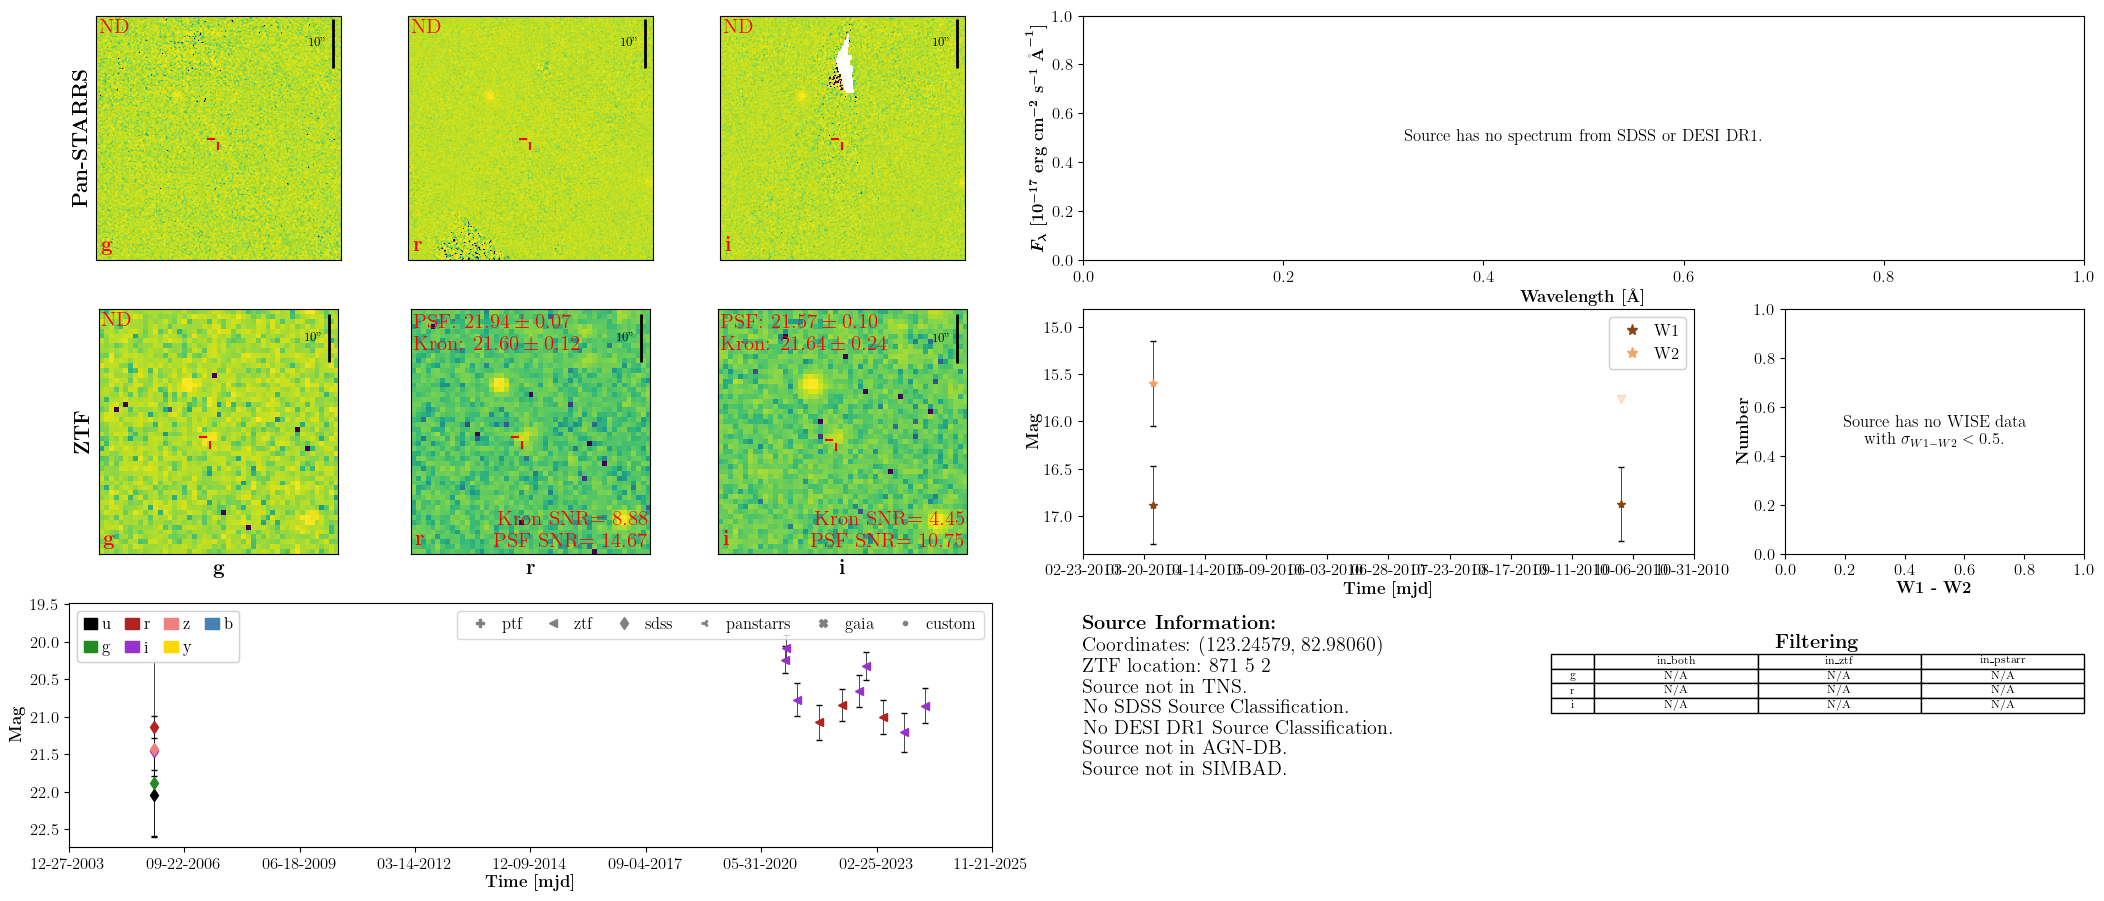

('lost', '000872', 1855)
Querying metadata from https://irsa.ipac.caltech.edu/ibe/search/ztf/products/deep?WHERE=field=000872+AND+ccdid=06+AND+qid=3

Image downloaded and saved at /var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/tmpnnjgpsrv/ztf_000872_zr_c06_q3_refimg.fits
Image downloaded and saved at /var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/tmp5ly9e22u/ztf_000872_zg_c06_q3_refimg.fits
Image downloaded and saved at /var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/tmpqgsrn5h_/ztf_000872_zi_c06_q3_refimg.fits
Querying ztf catalog for light curve...Querying wise catalog for light curve...

Querying neowise catalog for light curve...
Querying ptf catalog for light curve...
Querying sdss catalog for light curve...
Querying panstarrs catalog for light curve...
Querying gaia catalog for light curve...
Querying custom catalog for light curve...
Source at (146.95428449193233, 82.30389616027654) has no spectrum in SDSS.
Getting source spectrum from DESI DR1 (SPARCL)...
Source at (146.95

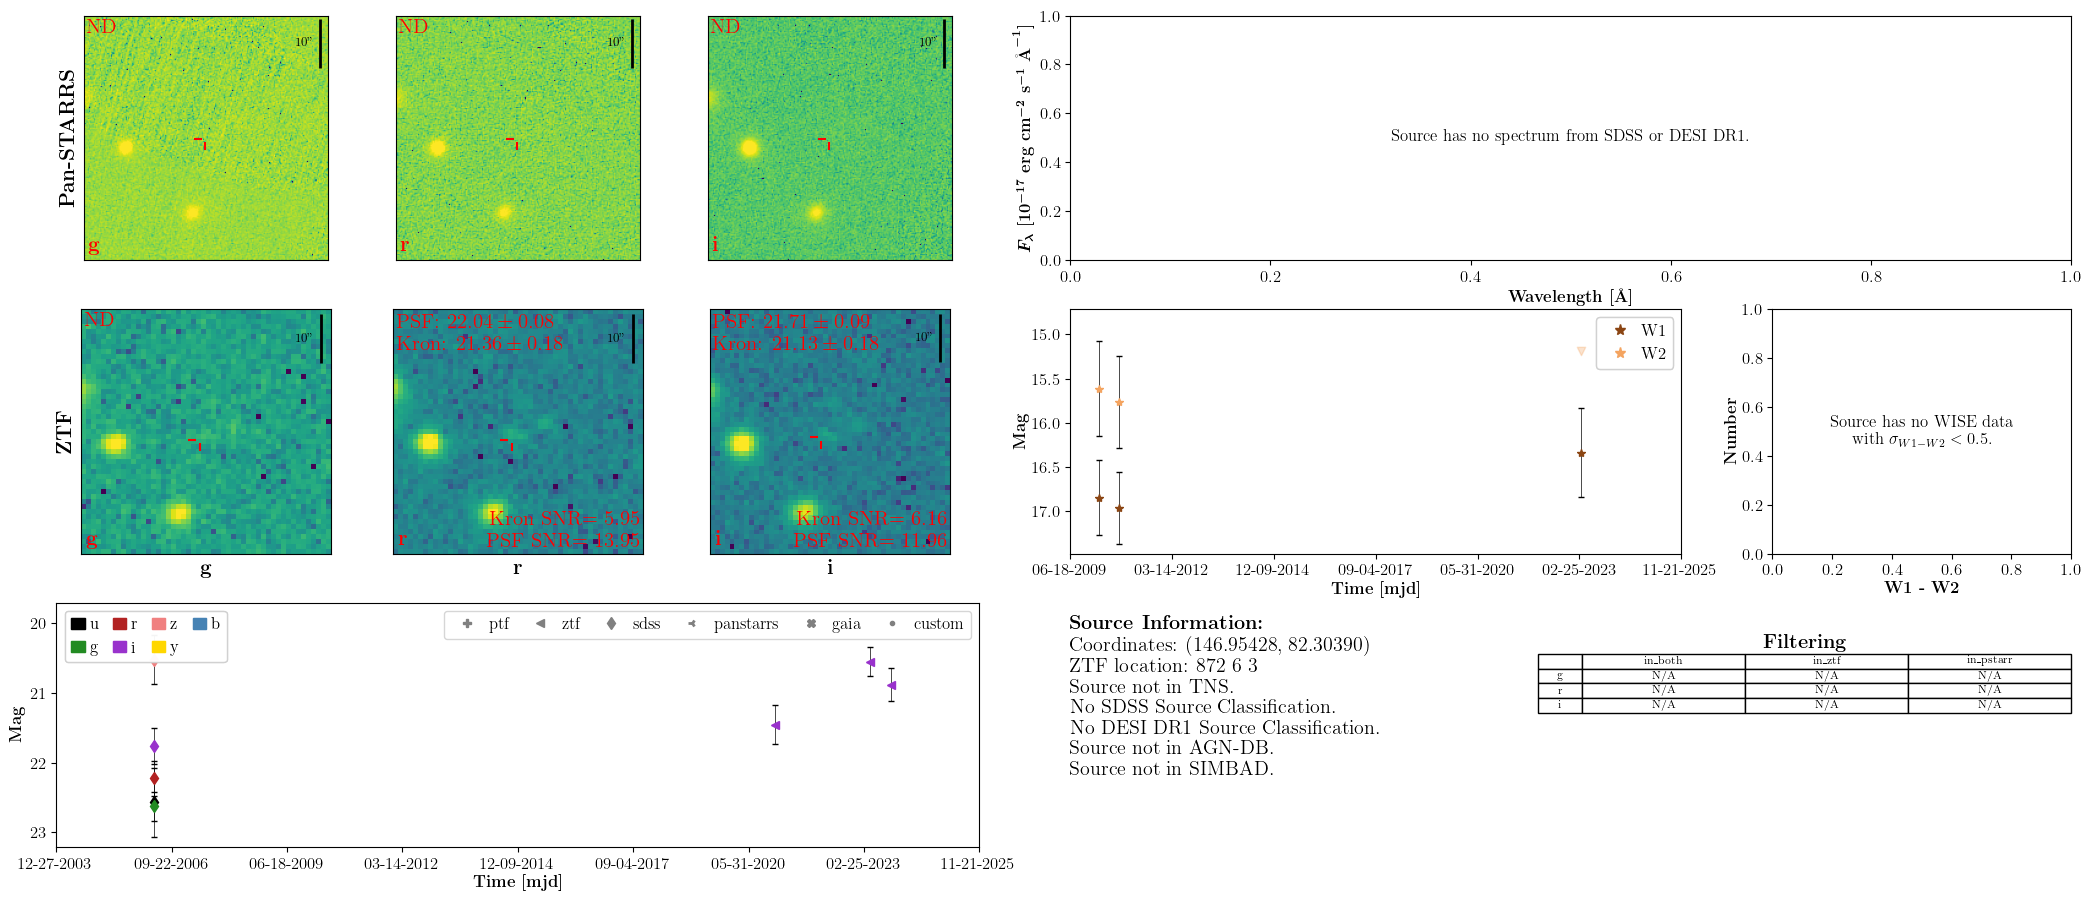

In [16]:
import matplotlib.pyplot as plt

for labs, src in cat1_srcs.items():
    print(labs)
    src.plot_everything()
    plt.show()